**Importing required libraries**

In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pickle_mapping = {
    'customer_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/customer_clean.pkl',
    'invent_movement_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/inventory_movement_clean.pkl',
    'lost_sales_log_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/lost_sales_log_clean.pkl',
    'open_invent_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/Open_inventory_clean.pkl',
    'price_changes_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/price_changes_cleaned.pkl',
    'products_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/Products_clean.pkl',
    'promotion_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/promotion_clean.pkl',
    'purchase_order_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/purchase_order_clean.pkl',
    'purchase_order_item_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/purchase_order_item_clean.pkl',
    'sales_return_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/sales_return_cleaned.pkl',
    'sales_return_items_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/sales_return_items_clean.pkl',
    'stores_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/stores_clean.pkl',
    'suppliers_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/suppliers_clean.pkl',
    'transaction_items_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/transaction_items_clean.pkl',
    'transactions_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/transactions_clean.pkl'

}

**Loading the datasets**

In [3]:
#storing the dataset in one cabinet(dataframes)
dataframes = {file_name: pd.read_pickle(file_path) for file_name,file_path in pickle_mapping.items()}

In [4]:
dataframes.keys()

dict_keys(['customer_df', 'invent_movement_df', 'lost_sales_log_df', 'open_invent_df', 'price_changes_df', 'products_df', 'promotion_df', 'purchase_order_df', 'purchase_order_item_df', 'sales_return_df', 'sales_return_items_df', 'stores_df', 'suppliers_df', 'transaction_items_df', 'transactions_df'])

In [5]:
data_name = ['customer_df', 'invent_movement_df', 'lost_sales_log_df', 'open_invent_df', 'price_changes_df', 'products_df', 'promotion_df', 'purchase_order_item_df', 'purchase_order_df', 'sales_return_df', 'sales_return_items_df', 'stores_df', 'suppliers_df', 'transaction_items_df', 'transactions_df']

### Loading all the dataset

In [6]:
customer_df=dataframes['customer_df']
invent_movement_df=dataframes['invent_movement_df']
lost_sales_log_df=dataframes['lost_sales_log_df']
open_invent_df=dataframes['open_invent_df']
price_changes_df=dataframes['price_changes_df']
products_df=dataframes['products_df']
promotion_df=dataframes['promotion_df']
purchase_order_item_df=dataframes['purchase_order_item_df']
purchase_order_df=dataframes['purchase_order_df']
sales_return_df=dataframes['sales_return_df']
stores_df=dataframes['stores_df']
suppliers_df=dataframes['suppliers_df']
transaction_items_df=dataframes['transaction_items_df']
transactions_df=dataframes['transactions_df']

# Exploratory Data Anlysis (EDA)

## Sales Intelligence
**KPIs**
 - Net sales and gross margin
 - Average basket value and units per basket
 - Product and category distribution
 - Promotion uplift and margin impact

**Net sales and gross margin**

In [7]:
# Filtering out voided sales
transactions_complete_df = transactions_df[transactions_df['transaction_status']=='Completed']

In [8]:
print(transactions_df.shape)                   # We have 1496 incomplete transactions
print(transactions_complete_df.shape)

(100000, 10)
(98504, 10)


**Joining the transaction and transaction_items datasets**

In [9]:
trans_df=pd.merge(
    transaction_items_df,
    transactions_complete_df[['transaction_id','transaction_datetime','store_id','customer_id','payment_method']],
    on='transaction_id',
    how='inner'
)

trans_df.head(10)

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method
0,TXN0000001,1,P122,1,120.0,0.0,87.71,120.0,120.0,NA,2025-01-01 08:16:00,ST02,CUST02120,Cash
1,TXN0000002,1,P057,1,200.0,0.0,137.06,200.0,200.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa
2,TXN0000002,2,P079,2,48.0,0.0,36.69,96.0,96.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa
3,TXN0000003,1,P056,1,160.0,0.0,125.81,160.0,160.0,NA,2025-01-01 08:59:00,ST06,CUST03048,Insurance
4,TXN0000004,1,P044,1,145.0,0.0,111.82,145.0,145.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa
5,TXN0000004,2,P062,2,80.0,0.0,60.07,160.0,160.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa
6,TXN0000005,1,P022,1,485.0,0.0,369.67,485.0,485.0,NA,2025-01-01 09:02:00,ST02,CUST00690,Cash
7,TXN0000006,1,P086,1,150.0,0.0,103.20,150.0,150.0,NA,2025-01-01 09:08:00,ST01,NaN,Cash
8,TXN0000006,2,P072,1,81.0,0.0,54.63,81.0,81.0,NA,2025-01-01 09:08:00,ST01,NaN,Cash
9,TXN0000006,3,P106,1,175.0,0.0,134.48,175.0,175.0,NA,2025-01-01 09:08:00,ST01,NaN,Cash


In [10]:
# checking all records per trasactions per line_product
trans_df.shape[1]

14

In [11]:
#Calculating net sales per each store before deducting the returned goods
total_sales_b4_returns = trans_df.groupby('store_id')['line_net_amount'].sum()

In [12]:
total_sales_b4_returns

store_id
ST01    5794218.65
ST02    5133402.75
ST03    4440826.55
ST04    4710191.30
ST05    3602625.15
ST06    4057265.55
ST07    4290289.20
ST08    3246847.25
ST09    3963158.35
ST10    4675793.70
ST11    3927787.95
ST12    3228958.35
Name: line_net_amount, dtype: float64

**calculating the total returns per store**

In [13]:
sales_return_df

,return_id,original_transaction_id,return_datetime,store_id,return_reason,refund_amount
0,RET000001,TXN0000029,2025-01-03 18:12:09,ST11,Product near expiry,150.0
1,RET000002,TXN0000802,2025-01-04 19:36:28,ST02,Wrong product dispensed,185.0
2,RET000003,TXN0000823,2025-01-05 01:52:24,ST02,Duplicate purchase,34.0
3,RET000004,TXN0001228,2025-01-06 22:55:17,ST01,Wrong product dispensed,150.0
4,RET000005,TXN0000152,2025-01-09 18:30:37,ST02,Damaged packaging,175.0
...,...,...,...,...,...,...
1025,RET001026,TXN0098024,2025-12-29 13:52:28,ST11,Duplicate purchase,515.0
1026,RET001027,TXN0094255,2025-12-29 17:15:07,ST06,Prescription changed,329.0
1027,RET001028,TXN0095674,2025-12-30 17:39:39,ST04,Damaged packaging,143.0
1028,RET001029,TXN0097460,2025-12-31 21:14:30,ST01,Customer changed mind,215.0


In [14]:
total_returns = sales_return_df.groupby('store_id')['refund_amount'].sum()

In [15]:
stores_df

,store_id,store_name,county,town,opening_date,store_status
0,ST01,SimPharm Westlands,Nairobi,Westlands,2016-03-14,Active
1,ST02,SimPharm Embakasi,Nairobi,Embakasi,2018-07-02,Active
2,ST03,SimPharm Nyali,Mombasa,Nyali,2017-02-20,Active
3,ST04,SimPharm Mombasa Island,Mombasa,Mombasa Island,2015-09-01,Active
4,ST05,SimPharm Milimani,Kisumu,Milimani,2019-05-13,Active
5,ST06,SimPharm Kisumu Central,Kisumu,Kisumu Central,2016-11-07,Active
6,ST07,SimPharm Nakuru Town,Nakuru,Nakuru Town,2017-06-19,Active
7,ST08,SimPharm Naivasha,Nakuru,Naivasha,2020-01-27,Active
8,ST09,SimPharm Thika,Kiambu,Thika,2018-03-12,Active
9,ST10,SimPharm Ruaka,Kiambu,Ruaka,2021-08-16,Active


**Combining the total sales before refunds and the total refunds per store datasets**

In [16]:
total_revenue_per_store =total_sales_b4_returns.to_frame().merge(
        total_returns,
        on='store_id',
        how='inner')\
        .merge(
            stores_df[['store_id','store_name','county']],
            on='store_id',
            how='inner'
        )
    
total_revenue_per_store

,store_id,line_net_amount,refund_amount,store_name,county
0,ST01,5794218.65,28968.55,SimPharm Westlands,Nairobi
1,ST02,5133402.75,22328.30,SimPharm Embakasi,Nairobi
2,ST03,4440826.55,19336.80,SimPharm Nyali,Mombasa
3,ST04,4710191.30,18472.00,SimPharm Mombasa Island,Mombasa
4,ST05,3602625.15,13295.35,SimPharm Milimani,Kisumu
5,ST06,4057265.55,15250.90,SimPharm Kisumu Central,Kisumu
6,ST07,4290289.20,14957.80,SimPharm Nakuru Town,Nakuru
7,ST08,3246847.25,17247.00,SimPharm Naivasha,Nakuru
8,ST09,3963158.35,18752.10,SimPharm Thika,Kiambu
9,ST10,4675793.70,17793.75,SimPharm Ruaka,Kiambu


**Calculating the net revenue each store made**

In [17]:
total_revenue_per_store["revenue"]=round(total_revenue_per_store['line_net_amount']-total_revenue_per_store['refund_amount'])
total_revenue_per_store

,store_id,line_net_amount,refund_amount,store_name,county,revenue
0,ST01,5794218.65,28968.55,SimPharm Westlands,Nairobi,5765250.0
1,ST02,5133402.75,22328.30,SimPharm Embakasi,Nairobi,5111074.0
2,ST03,4440826.55,19336.80,SimPharm Nyali,Mombasa,4421490.0
3,ST04,4710191.30,18472.00,SimPharm Mombasa Island,Mombasa,4691719.0
4,ST05,3602625.15,13295.35,SimPharm Milimani,Kisumu,3589330.0
5,ST06,4057265.55,15250.90,SimPharm Kisumu Central,Kisumu,4042015.0
6,ST07,4290289.20,14957.80,SimPharm Nakuru Town,Nakuru,4275331.0
7,ST08,3246847.25,17247.00,SimPharm Naivasha,Nakuru,3229600.0
8,ST09,3963158.35,18752.10,SimPharm Thika,Kiambu,3944406.0
9,ST10,4675793.70,17793.75,SimPharm Ruaka,Kiambu,4658000.0


**Sorting revenues by store**

In [18]:
total_revenue_per_store=total_revenue_per_store.sort_values('revenue',ascending=False)
total_revenue_per_store

,store_id,line_net_amount,refund_amount,store_name,county,revenue
0,ST01,5794218.65,28968.55,SimPharm Westlands,Nairobi,5765250.0
1,ST02,5133402.75,22328.30,SimPharm Embakasi,Nairobi,5111074.0
3,ST04,4710191.30,18472.00,SimPharm Mombasa Island,Mombasa,4691719.0
9,ST10,4675793.70,17793.75,SimPharm Ruaka,Kiambu,4658000.0
2,ST03,4440826.55,19336.80,SimPharm Nyali,Mombasa,4421490.0
6,ST07,4290289.20,14957.80,SimPharm Nakuru Town,Nakuru,4275331.0
5,ST06,4057265.55,15250.90,SimPharm Kisumu Central,Kisumu,4042015.0
8,ST09,3963158.35,18752.10,SimPharm Thika,Kiambu,3944406.0
10,ST11,3927787.95,15423.65,SimPharm Eldoret Town,Uasin Gishu,3912364.0
4,ST05,3602625.15,13295.35,SimPharm Milimani,Kisumu,3589330.0


**Visual for total revenue per store**

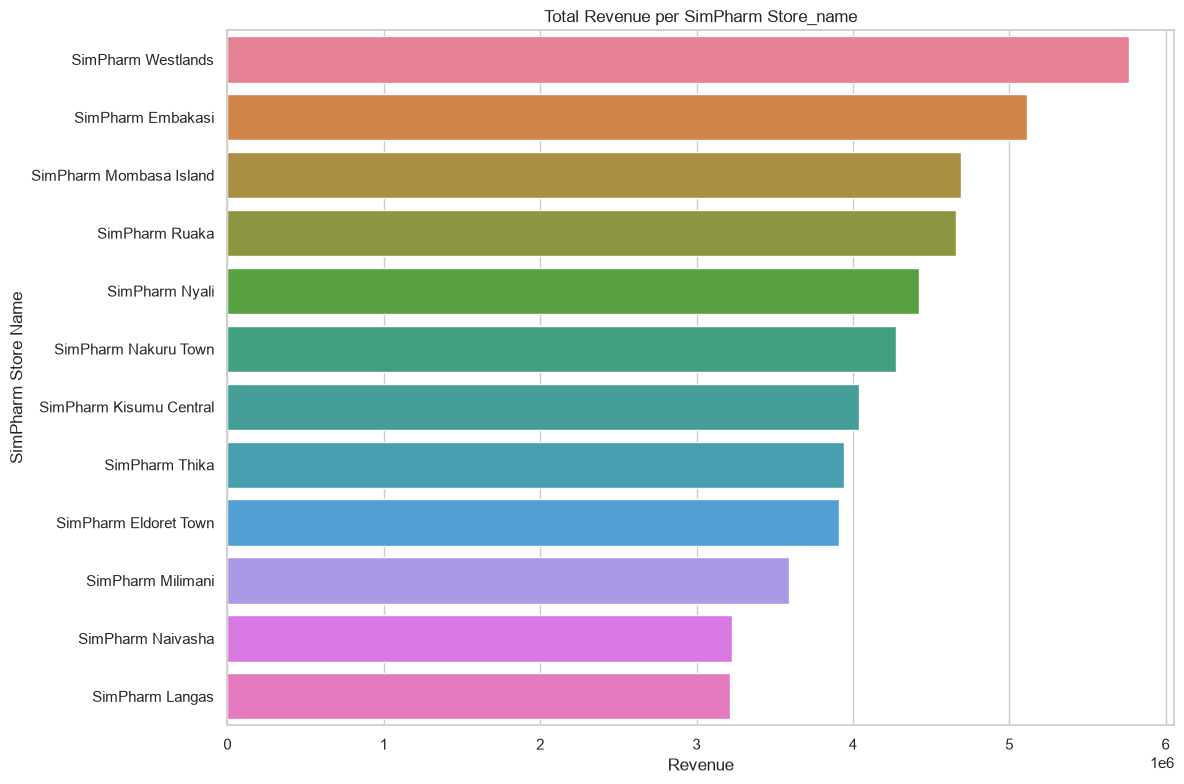

In [19]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=[12,8])
sns.barplot(data=total_revenue_per_store,x='revenue',y='store_name',hue='store_name')
plt.title('Total Revenue per SimPharm Store_name')
plt.xlabel('Revenue')
plt.ylabel('SimPharm Store Name')
plt.tight_layout()
plt.show()

**Calculating the gross_profit**

In [28]:
trans_df['profit']=round((trans_df['line_net_amount'])-(trans_df['unit_cost_at_sale']*trans_df['quantity']),2)

In [31]:
trans_df

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,profit
0,TXN0000001,1,P122,1,120.0,0.0,87.71,120.0,120.0,NA,2025-01-01 08:16:00,ST02,CUST02120,Cash,32.29
1,TXN0000002,1,P057,1,200.0,0.0,137.06,200.0,200.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,62.94
2,TXN0000002,2,P079,2,48.0,0.0,36.69,96.0,96.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,22.62
3,TXN0000003,1,P056,1,160.0,0.0,125.81,160.0,160.0,NA,2025-01-01 08:59:00,ST06,CUST03048,Insurance,34.19
4,TXN0000004,1,P044,1,145.0,0.0,111.82,145.0,145.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa,33.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244267,TXN0099998,2,P091,1,84.0,0.0,58.06,84.0,84.0,NA,2025-12-31 20:52:00,ST10,CUST03884,Cash,25.94
244268,TXN0099999,1,P005,1,110.0,0.0,88.14,110.0,110.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,21.86
244269,TXN0099999,2,P039,2,83.0,0.0,60.86,166.0,166.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,44.28
244270,TXN0099999,3,P150,1,98.0,0.0,66.20,98.0,98.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,31.80


**profits per store**

In [32]:
profits_per_store = trans_df.groupby('store_id')['profit'].sum()
profits_per_store

store_id
ST01    1518027.54
ST02    1345798.48
ST03    1158078.10
ST04    1225252.61
ST05     940066.37
ST06    1054534.44
ST07    1123336.39
ST08     848001.83
ST09    1031945.56
ST10    1221510.97
ST11    1021838.89
ST12     846832.03
Name: profit, dtype: float64

**merging the profits to total revenue table**

In [ ]:
total_revenue_per_store=pd.merge(
    total_revenue_per_store,
    profits_per_store.to_frame(),
    on='store_id',
    how='left'
)

**calculating the gross profif**

In [38]:
total_revenue_per_store['gross_profit']=round((total_revenue_per_store['profit'])-(total_revenue_per_store['refund_amount']),2)

In [40]:
total_revenue_per_store=total_revenue_per_store.sort_values('gross_profit',ascending=False)
total_revenue_per_store

,store_id,line_net_amount,refund_amount,store_name,county,revenue,profit,gross_profit
0,ST01,5794218.65,28968.55,SimPharm Westlands,Nairobi,5765250.0,1518027.54,1489058.99
1,ST02,5133402.75,22328.30,SimPharm Embakasi,Nairobi,5111074.0,1345798.48,1323470.18
2,ST04,4710191.30,18472.00,SimPharm Mombasa Island,Mombasa,4691719.0,1225252.61,1206780.61
3,ST10,4675793.70,17793.75,SimPharm Ruaka,Kiambu,4658000.0,1221510.97,1203717.22
4,ST03,4440826.55,19336.80,SimPharm Nyali,Mombasa,4421490.0,1158078.10,1138741.30
5,ST07,4290289.20,14957.80,SimPharm Nakuru Town,Nakuru,4275331.0,1123336.39,1108378.59
6,ST06,4057265.55,15250.90,SimPharm Kisumu Central,Kisumu,4042015.0,1054534.44,1039283.54
7,ST09,3963158.35,18752.10,SimPharm Thika,Kiambu,3944406.0,1031945.56,1013193.46
8,ST11,3927787.95,15423.65,SimPharm Eldoret Town,Uasin Gishu,3912364.0,1021838.89,1006415.24
9,ST05,3602625.15,13295.35,SimPharm Milimani,Kisumu,3589330.0,940066.37,926771.02


**Visualizing the gross profit per store**

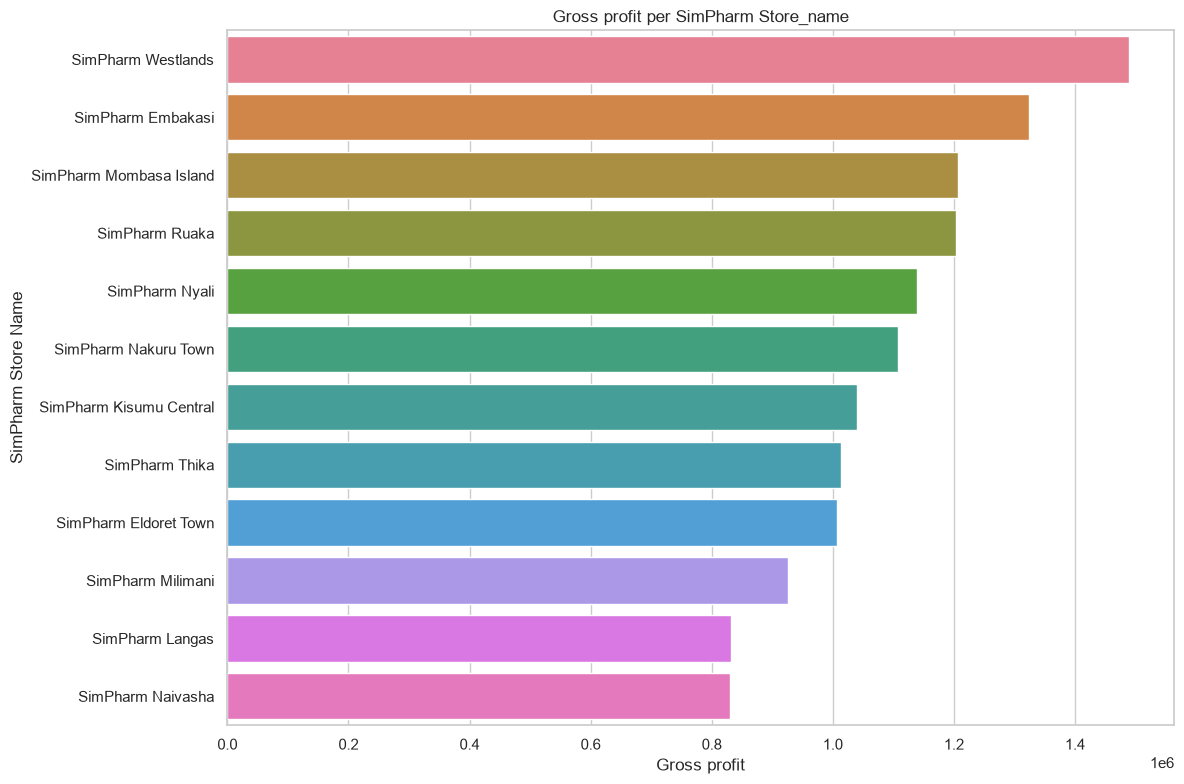

In [41]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=[12,8])
sns.barplot(data=total_revenue_per_store,x='gross_profit',y='store_name',hue='store_name')
plt.title('Gross profit per SimPharm Store_name')
plt.xlabel('Gross profit')
plt.ylabel('SimPharm Store Name')
plt.tight_layout()
plt.show()

**Calaculating the margins per store**

In [43]:
total_revenue_per_store['profit_margins'] = round((total_revenue_per_store['gross_profit'])/(total_revenue_per_store['revenue']),2)
total_revenue_per_store

,store_id,line_net_amount,refund_amount,store_name,county,revenue,profit,gross_profit,profit_margins
0,ST01,5794218.65,28968.55,SimPharm Westlands,Nairobi,5765250.0,1518027.54,1489058.99,0.26
1,ST02,5133402.75,22328.30,SimPharm Embakasi,Nairobi,5111074.0,1345798.48,1323470.18,0.26
2,ST04,4710191.30,18472.00,SimPharm Mombasa Island,Mombasa,4691719.0,1225252.61,1206780.61,0.26
3,ST10,4675793.70,17793.75,SimPharm Ruaka,Kiambu,4658000.0,1221510.97,1203717.22,0.26
4,ST03,4440826.55,19336.80,SimPharm Nyali,Mombasa,4421490.0,1158078.10,1138741.30,0.26
5,ST07,4290289.20,14957.80,SimPharm Nakuru Town,Nakuru,4275331.0,1123336.39,1108378.59,0.26
6,ST06,4057265.55,15250.90,SimPharm Kisumu Central,Kisumu,4042015.0,1054534.44,1039283.54,0.26
7,ST09,3963158.35,18752.10,SimPharm Thika,Kiambu,3944406.0,1031945.56,1013193.46,0.26
8,ST11,3927787.95,15423.65,SimPharm Eldoret Town,Uasin Gishu,3912364.0,1021838.89,1006415.24,0.26
9,ST05,3602625.15,13295.35,SimPharm Milimani,Kisumu,3589330.0,940066.37,926771.02,0.26


### Average basket value

**average basket value by store**

In [54]:
avg_basket_value_per_store = trans_df.groupby('store_id')['line_net_amount'].mean().round(2)
avg_basket_value_per_store.to_frame()


,line_net_amount
store_id,
ST01,211.63
ST02,209.47
ST03,214.59
ST04,207.34
ST05,201.52
ST06,207.58
ST07,214.27
ST08,210.97
ST09,196.63


In [53]:
avg_basket_value_per_payment_method=trans_df.groupby('payment_method')['line_net_amount'].mean().round(2)
avg_basket_value_per_payment_method.to_frame()

,line_net_amount
payment_method,
Card,208.79
Cash,210.50
Insurance,208.79
M-Pesa,208.59


In [55]:
trans_df['payment_method'].value_counts()

payment_method
M-Pesa       146830
Cash          58481
Card          24339
Insurance     14622
Name: count, dtype: int64

In [44]:
trans_df

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,profit
0,TXN0000001,1,P122,1,120.0,0.0,87.71,120.0,120.0,NA,2025-01-01 08:16:00,ST02,CUST02120,Cash,32.29
1,TXN0000002,1,P057,1,200.0,0.0,137.06,200.0,200.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,62.94
2,TXN0000002,2,P079,2,48.0,0.0,36.69,96.0,96.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,22.62
3,TXN0000003,1,P056,1,160.0,0.0,125.81,160.0,160.0,NA,2025-01-01 08:59:00,ST06,CUST03048,Insurance,34.19
4,TXN0000004,1,P044,1,145.0,0.0,111.82,145.0,145.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa,33.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244267,TXN0099998,2,P091,1,84.0,0.0,58.06,84.0,84.0,NA,2025-12-31 20:52:00,ST10,CUST03884,Cash,25.94
244268,TXN0099999,1,P005,1,110.0,0.0,88.14,110.0,110.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,21.86
244269,TXN0099999,2,P039,2,83.0,0.0,60.86,166.0,166.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,44.28
244270,TXN0099999,3,P150,1,98.0,0.0,66.20,98.0,98.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,31.80


### product contribution share

**Investigating top 10 products generating the highest revenue and highest profit**

In [ ]:
#top_10 higest revenue generating product

revenue_by_product = trans_df.groupby('product_id')['line_net_amount'].sum()
revenue_by_product.to_frame()
#top ten high revenue generating  products
revenue_by_product=revenue_by_product.to_frame().sort_values('line_net_amount',ascending=False)
revenue_by_product

,line_net_amount
product_id,
P060,1773372.0
P097,1292677.0
P084,1261800.0
P092,1067771.0
P099,1066755.0
...,...
P082,63719.4
P073,62974.0
P126,45994.0


In [70]:
# merging the products names and categories
revenue_by_product=pd.merge(
    revenue_by_product,
    products_df[['product_id','product_name','category']],
    on = 'product_id',
    how = 'left'
)
revenue_by_product.head(10)

,product_id,line_net_amount,product_name,category
0,P060,1773372.0,Blood glucose test strips 50 strips Test strips,Diabetes
1,P097,1292677.0,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements
2,P084,1261800.0,Beclometasone 100 mcg/dose Inhaler,Respiratory & Allergy
3,P092,1067771.0,Multivitamin Tablets,Vitamins & Supplements
4,P099,1066755.0,Omega-3 fish oil 1000 mg Softgel capsules,Vitamins & Supplements
5,P059,965004.5,Human insulin (isophane) 100 IU/mL Injection,Diabetes
6,P058,920040.0,Human insulin (soluble) 100 IU/mL Injection,Diabetes
7,P033,912145.5,Artemether/Lumefantrine 20/120 mg Tablets,Antimalarials
8,P044,869615.0,Losartan 50 mg Tablets,Cardiovascular
9,P065,853895.0,Aluminium hydroxide/Magnesium hydroxide Suspen...,Gastrointestinal


In [73]:
#top 10 highest profit generating product
profit_by_product = trans_df.groupby('product_id')['profit'].sum().round(2)
profit_by_product.to_frame()
#top ten high profit generating  products
profit_by_product=profit_by_product.to_frame().sort_values('profit',ascending=False)
profit_by_product

,profit
product_id,
P060,578945.64
P097,339561.68
P059,265880.40
P092,259225.96
P083,258327.49
...,...
P089,15376.29
P075,14833.85
P038,13915.62


In [74]:
# merging the products names and categories
profit_by_product=pd.merge(
    profit_by_product,
    products_df[['product_id','product_name','category']],
    on = 'product_id',
    how = 'left'
)
profit_by_product.head(10)

,product_id,profit,product_name,category
0,P060,578945.64,Blood glucose test strips 50 strips Test strips,Diabetes
1,P097,339561.68,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements
2,P059,265880.40,Human insulin (isophane) 100 IU/mL Injection,Diabetes
3,P092,259225.96,Multivitamin Tablets,Vitamins & Supplements
4,P083,258327.49,Montelukast 10 mg Tablets,Respiratory & Allergy
5,P131,254999.36,Levonorgestrel 1.5 mg Tablets,Reproductive Health
6,P058,248840.52,Human insulin (soluble) 100 IU/mL Injection,Diabetes
7,P033,240123.60,Artemether/Lumefantrine 20/120 mg Tablets,Antimalarials
8,P084,234053.28,Beclometasone 100 mcg/dose Inhaler,Respiratory & Allergy
9,P099,231361.88,Omega-3 fish oil 1000 mg Softgel capsules,Vitamins & Supplements


### Checking in each store which product is generating the highest profit and revenue

In [85]:

# Aggregate revenue by store and product
revenue_by_product_store = (trans_df.groupby(['store_id', 'product_id'], as_index=False)
['line_net_amount'].sum().rename(columns={'line_net_amount': 'total_revenue'}))

# Merge product names and categories
revenue_by_product_store = revenue_by_product_store.merge(
    products_df[['product_id', 'product_name', 'category']],
    on='product_id',
    how='left'
)
# Merge store names
revenue_by_product_store = revenue_by_product_store.merge(
    stores_df[['store_id', 'store_name']],
    on='store_id',
    how='left'
)
# Rank products within each store
revenue_by_product_store['rank'] = revenue_by_product_store.groupby('store_id')['total_revenue'].rank(method='first', ascending=False).astype(int)

#Select the top 10 products for each store
top_10_products_per_store = revenue_by_product_store[
        revenue_by_product_store['rank'] <= 10].sort_values(['store_id', 'rank']).reset_index(drop=True)


top_10_products_per_store


,store_id,product_id,total_revenue,product_name,category,store_name,rank
0,ST01,P060,236572.0,Blood glucose test strips 50 strips Test strips,Diabetes,SimPharm Westlands,1
1,ST01,P097,153497.0,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements,SimPharm Westlands,2
2,ST01,P092,146876.0,Multivitamin Tablets,Vitamins & Supplements,SimPharm Westlands,3
3,ST01,P084,140962.5,Beclometasone 100 mcg/dose Inhaler,Respiratory & Allergy,SimPharm Westlands,4
4,ST01,P099,134058.5,Omega-3 fish oil 1000 mg Softgel capsules,Vitamins & Supplements,SimPharm Westlands,5
...,...,...,...,...,...,...,...
115,ST12,P076,64018.5,Salbutamol 100 mcg/dose Inhaler,Respiratory & Allergy,SimPharm Langas,6
116,ST12,P131,60175.0,Levonorgestrel 1.5 mg Tablets,Reproductive Health,SimPharm Langas,7
117,ST12,P146,58655.5,Disposable examination gloves,First Aid & Medical Supplies,SimPharm Langas,8
118,ST12,P092,55589.5,Multivitamin Tablets,Vitamins & Supplements,SimPharm Langas,9


In [88]:
# Aggregate profits by store and product
profit_by_product_store = (trans_df.groupby(['store_id', 'product_id'], as_index=False)
['profit'].sum().round(2).rename(columns={'profit': 'total_profit'}))

# Merge product names and categories
profit_by_product_store = profit_by_product_store.merge(
    products_df[['product_id', 'product_name', 'category']],
    on='product_id',
    how='left'
)
# Merge store names
profit_by_product_store = profit_by_product_store.merge(
    stores_df[['store_id', 'store_name']],
    on='store_id',
    how='left'
)
# Rank products within each store
profit_by_product_store['rank'] = profit_by_product_store.groupby('store_id')['total_profit'].rank(method='first', ascending=False).astype(int)

#Select the top 10 products for each store
top_10_products_per_store_prof = profit_by_product_store[
        profit_by_product_store['rank'] <= 10].sort_values(['store_id', 'rank']).reset_index(drop=True)


top_10_products_per_store_prof

,store_id,product_id,total_profit,product_name,category,store_name,rank
0,ST01,P060,76767.25,Blood glucose test strips 50 strips Test strips,Diabetes,SimPharm Westlands,1
1,ST01,P097,40307.30,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements,SimPharm Westlands,2
2,ST01,P131,40142.32,Levonorgestrel 1.5 mg Tablets,Reproductive Health,SimPharm Westlands,3
3,ST01,P092,35618.44,Multivitamin Tablets,Vitamins & Supplements,SimPharm Westlands,4
4,ST01,P099,29634.36,Omega-3 fish oil 1000 mg Softgel capsules,Vitamins & Supplements,SimPharm Westlands,5
...,...,...,...,...,...,...,...
115,ST12,P097,17233.82,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements,SimPharm Langas,6
116,ST12,P076,16532.54,Salbutamol 100 mcg/dose Inhaler,Respiratory & Allergy,SimPharm Langas,7
117,ST12,P112,15473.17,Benzoyl peroxide 5% Gel,Dermatology,SimPharm Langas,8
118,ST12,P146,15150.40,Disposable examination gloves,First Aid & Medical Supplies,SimPharm Langas,9


**Something worth noting:**
 - the pharma product generating both high profit and revenue is Blood glucose test strips 50 strips Test strips which is in Diabetes category

### promotion uplift and margin impact

In [98]:
# Checking average quantity of products sold during promotion period 
quantity_promo_period = trans_df[trans_df['promotion_id']!='NA']

quantity_non_promo_period = trans_df[trans_df['promotion_id']=='NA']


In [101]:
quantity_promo_period

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,profit
3338,TXN0001342,2,P045,2,67.0,6.70,44.96,134.0,127.30,PROMO001,2025-07-01 10:49:00,ST01,CUST00319,M-Pesa,37.38
3602,TXN0001455,3,P045,2,67.0,6.70,44.96,134.0,127.30,PROMO001,2025-07-01 16:20:00,ST02,NaN,M-Pesa,37.38
3708,TXN0001499,3,P045,3,67.0,10.05,44.96,201.0,190.95,PROMO001,2025-07-01 17:41:00,ST02,CUST03619,M-Pesa,56.07
3736,TXN0001512,1,P045,2,67.0,6.70,44.96,134.0,127.30,PROMO001,2025-07-01 18:32:00,ST07,CUST00573,M-Pesa,37.38
4276,TXN0001733,1,P045,1,67.0,3.35,44.96,67.0,63.65,PROMO001,2025-08-01 20:13:00,ST03,CUST00353,M-Pesa,18.69
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208221,TXN0085260,2,P038,1,58.0,2.90,38.77,58.0,55.10,PROMO060,2025-11-18 12:25:00,ST06,CUST01530,M-Pesa,16.33
208296,TXN0085293,1,P038,1,58.0,2.90,38.77,58.0,55.10,PROMO060,2025-11-18 13:29:00,ST10,CUST05886,M-Pesa,16.33
208740,TXN0085470,1,P038,1,58.0,2.90,38.77,58.0,55.10,PROMO060,2025-11-18 18:25:00,ST10,CUST02238,Cash,16.33
209189,TXN0085655,2,P038,1,58.0,2.90,38.77,58.0,55.10,PROMO060,2025-11-19 12:18:00,ST12,CUST02058,M-Pesa,16.33


In [99]:
trans_df

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,profit
0,TXN0000001,1,P122,1,120.0,0.0,87.71,120.0,120.0,NA,2025-01-01 08:16:00,ST02,CUST02120,Cash,32.29
1,TXN0000002,1,P057,1,200.0,0.0,137.06,200.0,200.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,62.94
2,TXN0000002,2,P079,2,48.0,0.0,36.69,96.0,96.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,22.62
3,TXN0000003,1,P056,1,160.0,0.0,125.81,160.0,160.0,NA,2025-01-01 08:59:00,ST06,CUST03048,Insurance,34.19
4,TXN0000004,1,P044,1,145.0,0.0,111.82,145.0,145.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa,33.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244267,TXN0099998,2,P091,1,84.0,0.0,58.06,84.0,84.0,NA,2025-12-31 20:52:00,ST10,CUST03884,Cash,25.94
244268,TXN0099999,1,P005,1,110.0,0.0,88.14,110.0,110.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,21.86
244269,TXN0099999,2,P039,2,83.0,0.0,60.86,166.0,166.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,44.28
244270,TXN0099999,3,P150,1,98.0,0.0,66.20,98.0,98.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,31.80


In [105]:
trans_df.to_csv('transactions.csv',index=False)

In [106]:
promotion_df

,promotion_id,promotion_name,promotion_type,product_id,category,start_date,end_date,discount_type,discount_value
0,PROMO001,Hydrochlorothiazide 25 mg Tablets - 5% off,Product-level,P045,Not Provided,2025-01-07,2025-01-20,Percentage,5.0
1,PROMO002,Dermatology promotion - 10% off,Category-level,No Promotion,Dermatology,2025-01-10,2025-01-16,Percentage,10.0
2,PROMO003,Surgical spirit Solution - 20% off,Product-level,P139,Not Provided,2025-01-11,2025-01-24,Percentage,20.0
3,PROMO004,Omega-3 fish oil 1000 mg Softgel capsules - 20...,Product-level,P099,Not Provided,2025-01-18,2025-01-27,Percentage,20.0
4,PROMO005,Other Anti-infectives promotion - 5% off,Category-level,No Promotion,Other Anti-infectives,2025-01-23,2025-02-05,Percentage,5.0
5,PROMO006,Other Anti-infectives promotion - 10% off,Category-level,No Promotion,Other Anti-infectives,2025-01-31,2025-02-20,Percentage,10.0
6,PROMO007,Dihydroartemisinin/Piperaquine 40/320 mg Table...,Product-level,P035,Not Provided,2025-02-08,2025-02-21,Percentage,5.0
7,PROMO008,Alcohol hand sanitiser 70% Gel - 20% off,Product-level,P147,Not Provided,2025-02-09,2025-03-01,Percentage,20.0
8,PROMO009,Mefenamic acid 500 mg Capsules - 20% off,Product-level,P009,Not Provided,2025-02-11,2025-02-17,Percentage,20.0
9,PROMO010,Azithromycin 500 mg Tablets - 20% off,Product-level,P017,Not Provided,2025-03-06,2025-03-15,Percentage,20.0
